# Supermarket Sales — Exploratory Data Analysis (EDA)

## 1. Project Introduction

**What the dataset represents:** 1,000 supermarket sales transactions from three branches (A, B, C) in three cities in Myanmar, recorded between **1 January 2019 and 30 March 2019**. Each row is one invoice and includes the product line, quantity, price, payment method, customer type, gender, date/time and a customer rating.

**What this project tries to discover:**
- Which branches, product lines and payment methods bring the most sales?
- When are the busiest sales periods (hour, weekday, month)?
- Which variables are related to the sale amount?

**Why EDA is useful:** Exploratory Data Analysis helps us understand the data *before* making decisions. It lets us check data quality, spot patterns and unusual values, and form business questions that can be answered with evidence.

> This project is **only EDA** — no machine learning is used.

## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Global plot style so all charts look consistent
sns.set_theme(style="whitegrid")
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

## 3. Load Dataset

We load the CSV and take a first look. We always inspect the real data first: shape, column names, data types and a statistical summary.

In [2]:
df = pd.read_csv("../data/supermarket_sales.csv")
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [3]:
df.shape

(1000, 17)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   str    
 1   Branch                   1000 non-null   str    
 2   City                     1000 non-null   str    
 3   Customer type            1000 non-null   str    
 4   Gender                   1000 non-null   str    
 5   Product line             1000 non-null   str    
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null   float64
 10  Date                     1000 non-null   str    
 11  Time                     1000 non-null   str    
 12  Payment                  1000 non-null   str    
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  1000 non-nu

In [5]:
df.describe()

,Unit price,Quantity,Tax 5%,Total,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,0.000000,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905,49.650000,10.00000


In [6]:
# Column names and data types
print(df.columns.tolist())
print('---'*20)
print(df.dtypes)

['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating']
------------------------------------------------------------
Invoice ID                     str
Branch                         str
City                           str
Customer type                  str
Gender                         str
Product line                   str
Unit price                 float64
Quantity                     int64
Tax 5%                     float64
Total                      float64
Date                           str
Time                           str
Payment                        str
cogs                       float64
gross margin percentage    float64
gross income               float64
Rating                     float64
dtype: object


In [7]:
# Unique values of the categorical columns
for col in ["Branch", "City", "Customer type", "Gender", "Product line", "Payment"]:
    print(col, "->", df[col].nunique(), "unique:", df[col].unique().tolist())

Branch -> 3 unique: ['A', 'C', 'B']
City -> 3 unique: ['Yangon', 'Naypyitaw', 'Mandalay']
Customer type -> 2 unique: ['Member', 'Normal']
Gender -> 2 unique: ['Female', 'Male']
Product line -> 6 unique: ['Health and beauty', 'Electronic accessories', 'Home and lifestyle', 'Sports and travel', 'Food and beverages', 'Fashion accessories']
Payment -> 3 unique: ['Ewallet', 'Cash', 'Credit card']


**What we notice:**
- 1,000 rows and 17 columns, and `Invoice ID` is unique for every row.
- `Date` and `Time` are stored as plain text — we will convert them.
- `Branch` and `City` look like the same information. We check that below.
- `gross margin percentage` looks constant (std = 0). We check that below as well.

In [8]:
# Does each Branch map to exactly one City?
pd.crosstab(df["Branch"], df["City"])

City,Mandalay,Naypyitaw,Yangon
Branch,,,
A,0,0,340
B,332,0,0
C,0,328,0


Each branch belongs to exactly one city (A = Yangon, B = Mandalay, C = Naypyitaw), so `Branch` and `City` carry the **same** information. From now on we use `Branch` in the analysis.

## 4. Data Cleaning

We check for missing values and duplicates. We only change the data when there is a real reason, and we explain every decision.

In [9]:
print("Missing values per column:")
print(df.isnull().sum())
print('----'*20)
print("Duplicated rows:", df.duplicated().sum())
print("Duplicated Invoice IDs:", df["Invoice ID"].duplicated().sum())

Missing values per column:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64
--------------------------------------------------------------------------------
Duplicated rows: 0
Duplicated Invoice IDs: 0


**Decision:** there are **no missing values** and **no duplicates**, so we do **not** delete or fill anything.

Next, a few light cleaning steps that do not remove any data:
1. Rename the columns to simple names without spaces or symbols (easier to type).
2. Convert `Date` and `Time` to real datetime types.

In [10]:
# 1) Rename columns (no spaces / symbols)
df = df.rename(columns={
    "Invoice ID": "Invoice_ID",
    "Customer type": "Customer_type",
    "Product line": "Product_line",
    "Unit price": "Unit_price",
    "Tax 5%": "Tax",
    "gross margin percentage": "Gross_margin_pct",
    "gross income": "Gross_income",
    "cogs": "Cogs",
})

# 2) Convert Date and Time. The dates look like month/day/year (e.g. 1/5/2019)
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")
df["Time"] = pd.to_datetime(df["Time"], format="%H:%M").dt.time

df.dtypes

Invoice_ID                     str
Branch                         str
City                           str
Customer_type                  str
Gender                         str
Product_line                   str
Unit_price                 float64
Quantity                     int64
Tax                        float64
Total                      float64
Date                datetime64[us]
Time                        object
Payment                        str
Cogs                       float64
Gross_margin_pct           float64
Gross_income               float64
Rating                     float64
dtype: object

### Checking how the money columns relate

Before analysing sales, let's make sure we understand `Cogs`, `Tax`, `Total` and `Gross_income`.

In [11]:
# Cogs = Unit price x Quantity ?   Tax = 5% of Cogs ?   Total = Cogs + Tax ?
print("Cogs = Unit_price * Quantity :", np.allclose(df["Unit_price"] * df["Quantity"], df["Cogs"]))
print("Tax = 5% of Cogs            :", np.allclose(df["Cogs"] * 0.05, df["Tax"]))
print("Total = Cogs + Tax          :", np.allclose(df["Cogs"] + df["Tax"], df["Total"]))
print("Gross_income == Tax         :", np.allclose(df["Gross_income"], df["Tax"]))
print("Gross_margin_pct unique     :", df["Gross_margin_pct"].unique())

Cogs = Unit_price * Quantity : True
Tax = 5% of Cogs            : True
Total = Cogs + Tax          : True
Gross_income == Tax         : True
Gross_margin_pct unique     : [4.76190476]


**Important findings about the data:**
- `Cogs` is actually `Unit price × Quantity` (the price **before tax**), and `Total = Cogs + 5% tax`.
- `Gross_income` is **identical** to `Tax`, and `Gross_margin_pct` is a constant value (4.76%). These two columns add no new information.

**Decision:** we keep these columns in the file (no data is deleted), but we will **not** treat `Gross_income` as real profit, and we will exclude the redundant columns from the correlation analysis. We use **`Total`** as our measure of sales (it includes tax).

## 5. Feature Understanding

| Column | Meaning | Type |
|---|---|---|
| `Invoice_ID` | Unique invoice number | Identifier (text) |
| `Branch` | Supermarket branch (A, B, C) | Categorical |
| `City` | City of the branch | Categorical |
| `Customer_type` | Member or Normal customer | Categorical |
| `Gender` | Customer gender | Categorical |
| `Product_line` | Product category (6 categories) | Categorical |
| `Unit_price` | Price of one unit | Numerical |
| `Quantity` | Number of units bought | Numerical (discrete) |
| `Tax` | 5% tax on the purchase | Numerical |
| `Total` | Final amount paid (price + tax) | Numerical |
| `Date` | Date of the sale | Datetime |
| `Time` | Time of the sale | Time |
| `Payment` | Payment method | Categorical |
| `Cogs` | Unit price × quantity (before tax) | Numerical |
| `Gross_margin_pct` | Constant 4.76% | Numerical (constant) |
| `Gross_income` | Same values as `Tax` | Numerical |
| `Rating` | Customer satisfaction rating (4–10) | Numerical |

### Time-based features
We create `Hour`, `Day_of_week`, and `Month` from the date and time columns.

In [12]:
df["Hour"] = pd.to_datetime(df["Time"].astype(str)).dt.hour
df["Day_of_week"] = df["Date"].dt.day_name()
df["Month"] = df["Date"].dt.month_name()

# Fixed orders so charts show days and months in a natural order
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
month_order = ["January", "February", "March"]

print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Number of different days:", df["Date"].nunique())
print("Hours covered:", df["Hour"].min(), "to", df["Hour"].max())
df[["Date", "Time", "Hour", "Day_of_week", "Month"]].head()

Date range: 2019-01-01 to 2019-03-30
Number of different days: 89
Hours covered: 10 to 20


C:\Users\Admin\AppData\Local\Temp\ipykernel_13588\3263588248.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Hour"] = pd.to_datetime(df["Time"].astype(str)).dt.hour


,Date,Time,Hour,Day_of_week,Month
0,2019-01-05,13:08:00,13,Saturday,January
1,2019-03-08,10:29:00,10,Friday,March
2,2019-03-03,13:23:00,13,Sunday,March
3,2019-01-27,20:33:00,20,Sunday,January
4,2019-02-08,10:37:00,10,Friday,February


## 6. Univariate Analysis

We look at one variable at a time. First, the categorical variables.

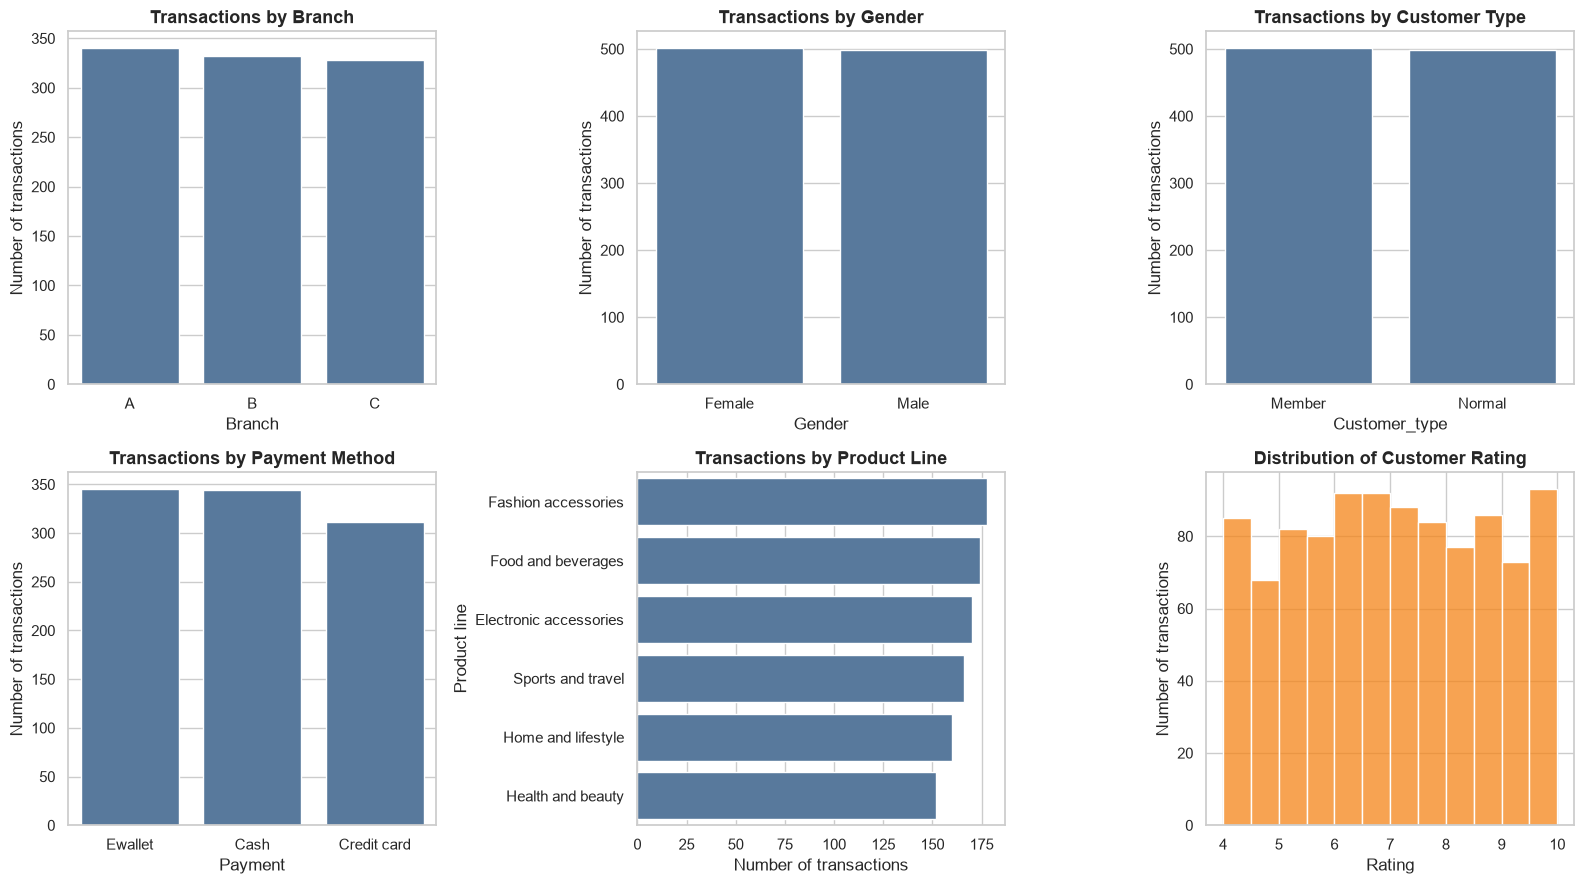

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

sns.countplot(data=df, x="Branch", ax=axes[0, 0], order=["A", "B", "C"], color="#4C78A8")
axes[0, 0].set_title("Transactions by Branch")

sns.countplot(data=df, x="Gender", ax=axes[0, 1], color="#4C78A8")
axes[0, 1].set_title("Transactions by Gender")

sns.countplot(data=df, x="Customer_type", ax=axes[0, 2], color="#4C78A8")
axes[0, 2].set_title("Transactions by Customer Type")

sns.countplot(data=df, x="Payment", ax=axes[1, 0], color="#4C78A8")
axes[1, 0].set_title("Transactions by Payment Method")

sns.countplot(data=df, y="Product_line", ax=axes[1, 1],
              order=df["Product_line"].value_counts().index, color="#4C78A8")
axes[1, 1].set_title("Transactions by Product Line")
axes[1, 1].set_xlabel("Number of transactions")

sns.histplot(data=df, x="Rating", bins=12, ax=axes[1, 2], color="#F58518")
axes[1, 2].set_title("Distribution of Customer Rating")
axes[1, 2].set_xlabel("Rating")
axes[1, 2].set_ylabel("Number of transactions")

for ax in [axes[0, 0], axes[0, 1], axes[0, 2], axes[1, 0]]:
    ax.set_ylabel("Number of transactions")
axes[1, 1].set_ylabel("Product line")

plt.tight_layout()
plt.savefig("../images/01_categorical_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
# Exact counts behind the charts
for col in ["Branch", "Gender", "Customer_type", "Payment", "Product_line"]:
    print(df[col].value_counts().to_string())
    print('---'*20)
print(df["Rating"].describe().round(2))

Branch
A    340
B    332
C    328
------------------------------------------------------------
Gender
Female    501
Male      499
------------------------------------------------------------
Customer_type
Member    501
Normal    499
------------------------------------------------------------
Payment
Ewallet        345
Cash           344
Credit card    311
------------------------------------------------------------
Product_line
Fashion accessories       178
Food and beverages        174
Electronic accessories    170
Sports and travel         166
Home and lifestyle        160
Health and beauty         152
------------------------------------------------------------
count    1000.00
mean        6.97
std         1.72
min         4.00
25%         5.50
50%         7.00
75%         8.50
max        10.00
Name: Rating, dtype: float64


**Reading the charts:**
- The dataset is very **balanced**: branches have 328–340 transactions each, and gender and customer type are almost 50/50.
- Payment methods are close to each other (Ewallet 345, Cash 344, Credit card 311).
- Ratings range from 4 to 10 and are spread fairly evenly, with a mean of about 7.0.

Now the numerical variables: sale amount, quantity and unit price.

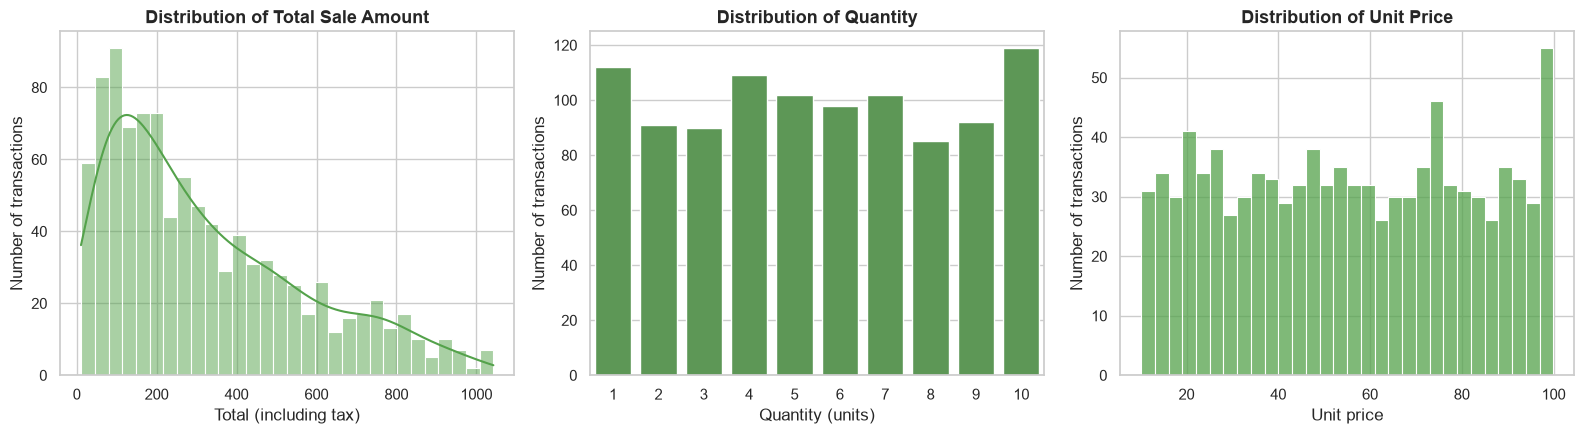

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(data=df, x="Total", bins=30, kde=True, ax=axes[0], color="#54A24B")
axes[0].set_title("Distribution of Total Sale Amount")
axes[0].set_xlabel("Total (including tax)")
axes[0].set_ylabel("Number of transactions")

sns.countplot(data=df, x="Quantity", ax=axes[1], color="#54A24B")
axes[1].set_title("Distribution of Quantity")
axes[1].set_xlabel("Quantity (units)")
axes[1].set_ylabel("Number of transactions")

sns.histplot(data=df, x="Unit_price", bins=30, ax=axes[2], color="#54A24B")
axes[2].set_title("Distribution of Unit Price")
axes[2].set_xlabel("Unit price")
axes[2].set_ylabel("Number of transactions")

plt.tight_layout()
plt.savefig("../images/02_numerical_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the charts:**
- `Total` is **right-skewed**: most invoices are small to medium, and fewer invoices are large (up to about 1,043).
- `Quantity` (1–10) and `Unit_price` (about 10–100) are spread fairly evenly, which is why `Total` (their product) piles up at the lower values.

## 7. Bivariate Analysis

Here we compare **sales (`Total`)** across categories and look at relationships between numerical variables.

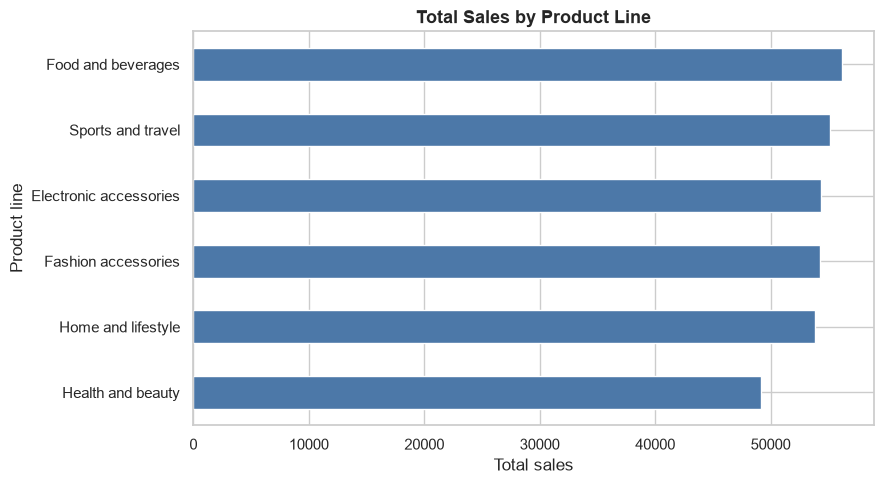

Product_line
Food and beverages        56144.84
Sports and travel         55122.83
Electronic accessories    54337.53
Fashion accessories       54305.90
Home and lifestyle        53861.91
Health and beauty         49193.74
Name: Total, dtype: float64

In [16]:
# Total sales per product line (sorted)
sales_by_product = df.groupby("Product_line")["Total"].sum().sort_values()

plt.figure(figsize=(9, 5))
sales_by_product.plot(kind="barh", color="#4C78A8")
plt.title("Total Sales by Product Line")
plt.xlabel("Total sales")
plt.ylabel("Product line")
plt.tight_layout()
plt.savefig("../images/03_sales_by_product_line.png", dpi=150, bbox_inches="tight")
plt.show()

sales_by_product.sort_values(ascending=False).round(2)

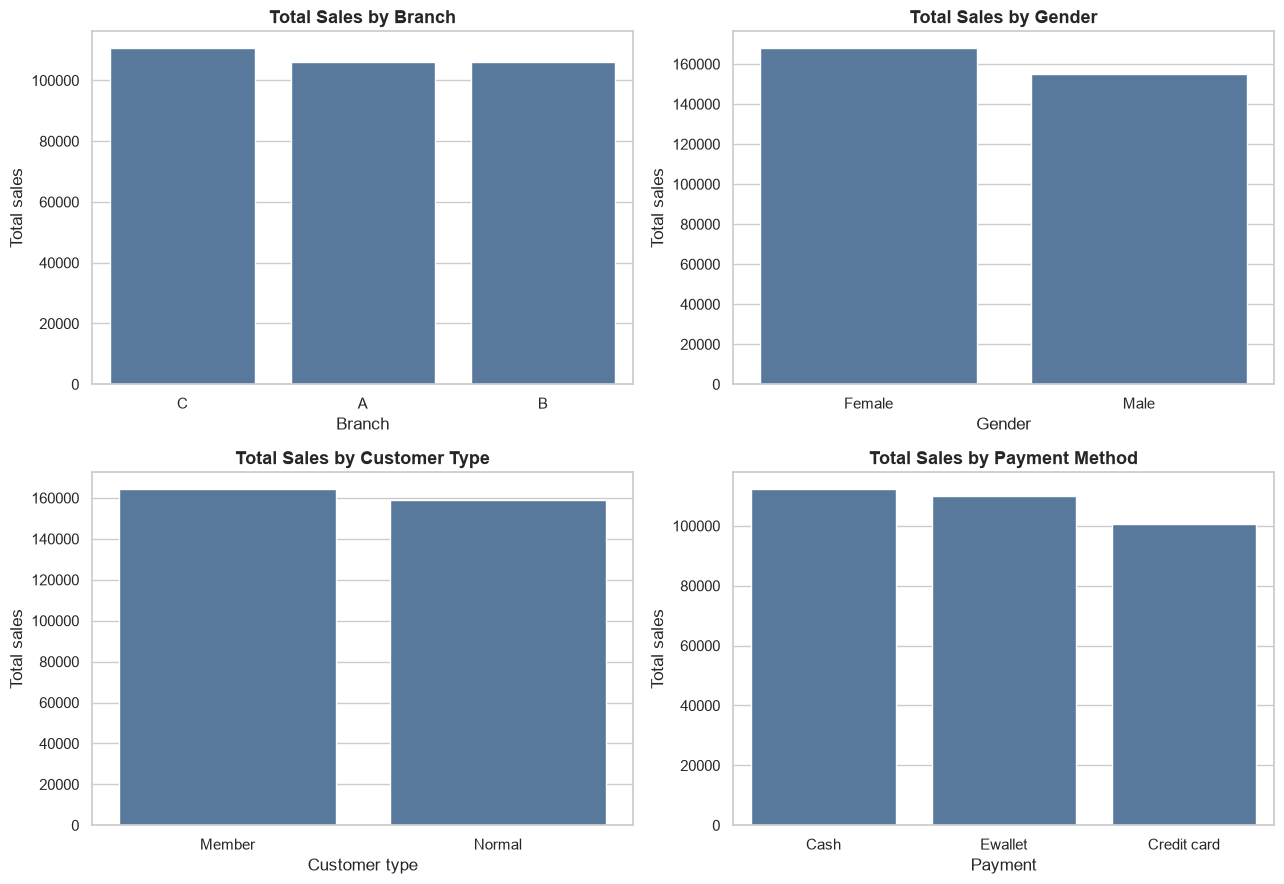

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col, title in zip(
    axes.flatten(),
    ["Branch", "Gender", "Customer_type", "Payment"],
    ["Total Sales by Branch", "Total Sales by Gender",
     "Total Sales by Customer Type", "Total Sales by Payment Method"],
):
    totals = df.groupby(col)["Total"].sum().sort_values(ascending=False)
    sns.barplot(x=totals.index, y=totals.values, ax=ax, color="#4C78A8")
    ax.set_title(title)
    ax.set_xlabel(col.replace("_", " "))
    ax.set_ylabel("Total sales")

plt.tight_layout()
plt.savefig("../images/04_sales_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
# The exact numbers: total, average and number of transactions
for col in ["Branch", "Gender", "Customer_type", "Payment"]:
    print(df.groupby(col)["Total"].agg(["sum", "mean", "count"]).round(2).sort_values("sum", ascending=False))
    print('---'*20)

              sum    mean  count
Branch                          
C       110568.71  337.10    328
A       106200.37  312.35    340
B       106197.67  319.87    332
------------------------------------------------------------
              sum    mean  count
Gender                          
Female  167882.92  335.10    501
Male    155083.82  310.79    499
------------------------------------------------------------
                     sum    mean  count
Customer_type                          
Member         164223.44  327.79    501
Normal         158743.30  318.12    499
------------------------------------------------------------
                   sum    mean  count
Payment                              
Cash         112206.57  326.18    344
Ewallet      109993.11  318.82    345
Credit card  100767.07  324.01    311
------------------------------------------------------------


**Reading the charts:**
- **Branch C** has the highest sales, but the gap with A and B is small (see the table).
- **Female** customers contribute more sales than male customers, and also have a higher average invoice.
- **Members** and Normal customers are very close.
- **Cash** has the highest sales; Credit card has the lowest because it also has fewer transactions.

Charts compare *totals*, so a group can win simply by having more transactions. That is why the tables also show the average and the count.

### Quantity vs Total and Rating vs Total

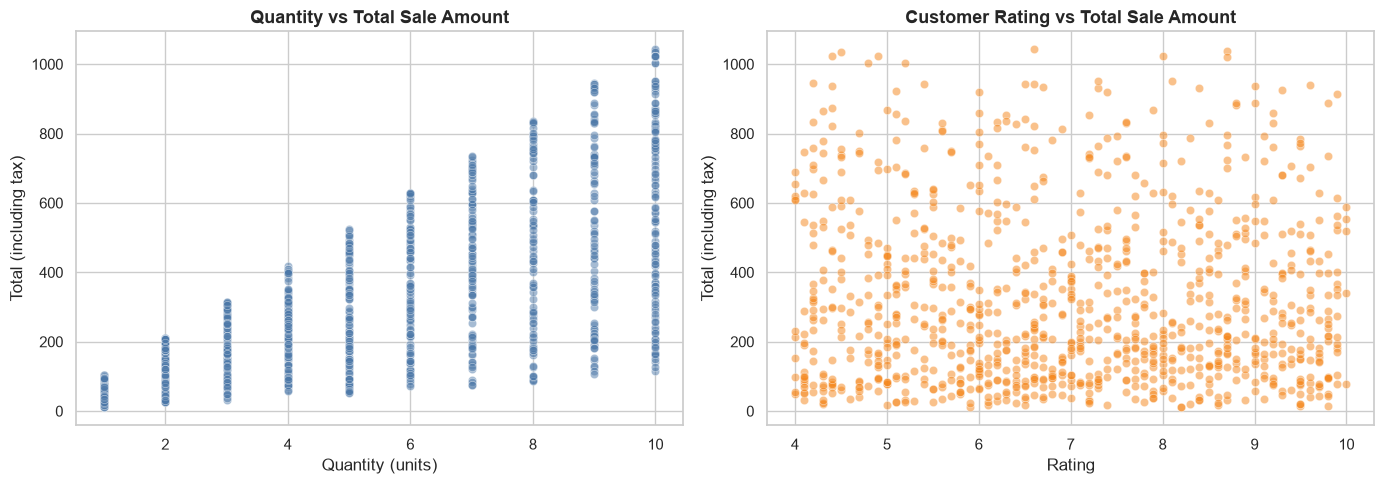

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x="Quantity", y="Total", alpha=0.5, ax=axes[0], color="#4C78A8")
axes[0].set_title("Quantity vs Total Sale Amount")
axes[0].set_xlabel("Quantity (units)")
axes[0].set_ylabel("Total (including tax)")

sns.scatterplot(data=df, x="Rating", y="Total", alpha=0.5, ax=axes[1], color="#F58518")
axes[1].set_title("Customer Rating vs Total Sale Amount")
axes[1].set_xlabel("Rating")
axes[1].set_ylabel("Total (including tax)")

plt.tight_layout()
plt.savefig("../images/05_scatter_quantity_rating.png", dpi=150, bbox_inches="tight")
plt.show()

- **Quantity vs Total:** there is a visible upward pattern — buying more units generally means a higher total — but the points are spread out because the unit price differs between products.
- **Rating vs Total:** no visible pattern. A higher rating does not appear to go with a higher or lower sale amount.

### Do branches sell different product lines?

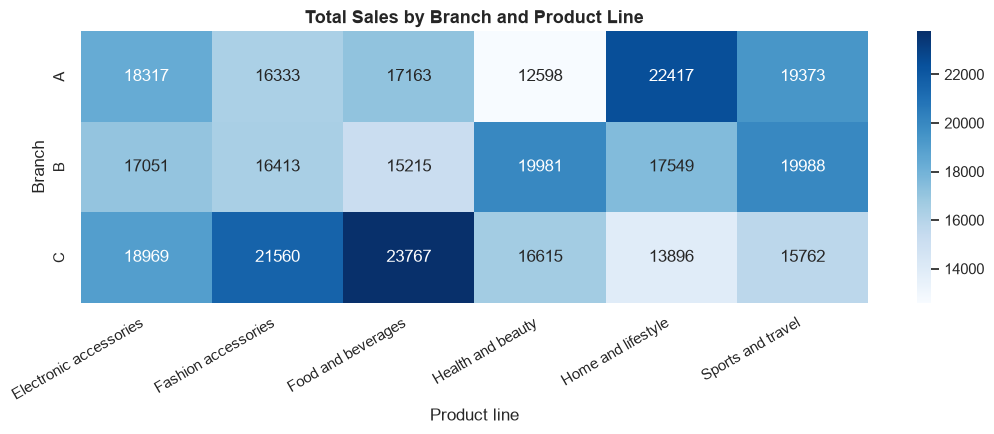

In [20]:
# Rows = branch, columns = product line, values = total sales
branch_product = df.pivot_table(index="Branch", columns="Product_line",
                                values="Total", aggfunc="sum")

plt.figure(figsize=(11, 4.5))
sns.heatmap(branch_product, annot=True, fmt=".0f", cmap="Blues")
plt.title("Total Sales by Branch and Product Line")
plt.xlabel("Product line")
plt.ylabel("Branch")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("../images/06_branch_product_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

Each branch has a different "best" product line: **A** sells most in *Home and lifestyle*, **B** in *Sports and travel* and *Health and beauty*, **C** in *Food and beverages*. Even though the branch totals are close, their product mix is quite different.

## 8. Time Analysis

Sales by hour, day of week and month.

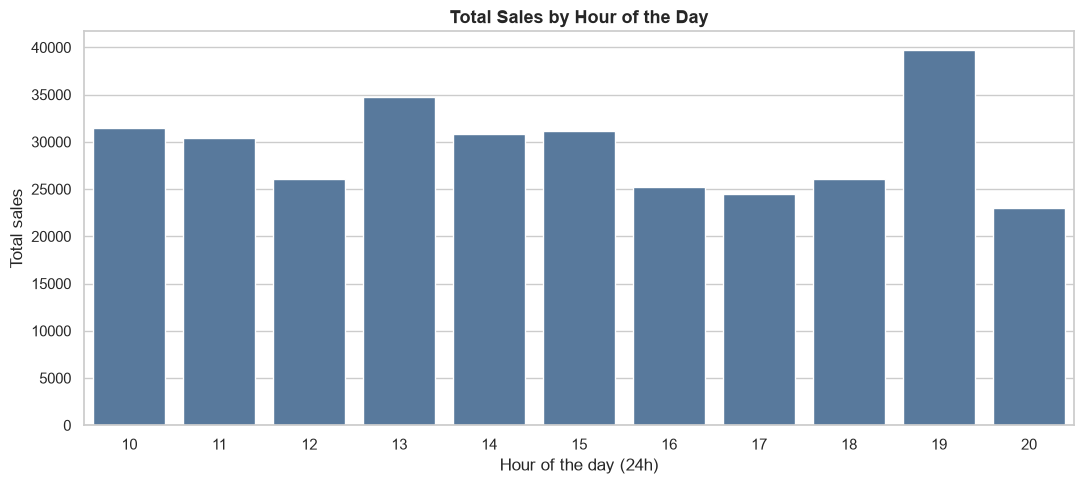

Hour
19    39699.51
13    34723.23
10    31421.48
Name: Total, dtype: float64


In [21]:
sales_by_hour = df.groupby("Hour")["Total"].sum()

plt.figure(figsize=(11, 5))
sns.barplot(x=sales_by_hour.index, y=sales_by_hour.values, color="#4C78A8")
plt.title("Total Sales by Hour of the Day")
plt.xlabel("Hour of the day (24h)")
plt.ylabel("Total sales")
plt.tight_layout()
plt.savefig("../images/07_sales_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

print(sales_by_hour.sort_values(ascending=False).head(3).round(2))

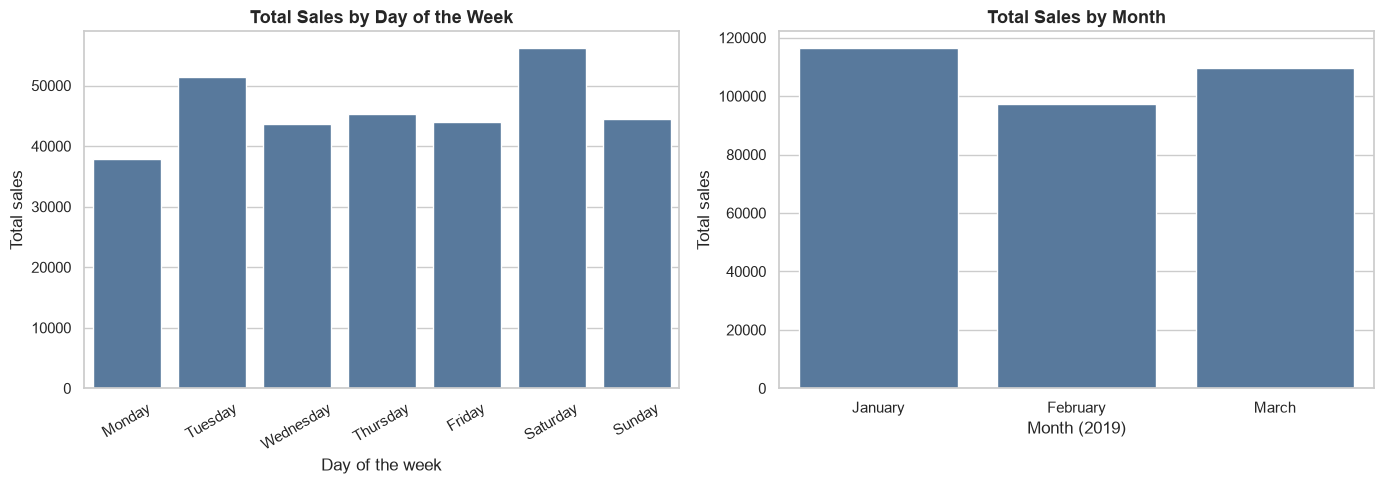

Day_of_week
Monday       37899.08
Tuesday      51482.25
Wednesday    43731.14
Thursday     45349.25
Friday       43926.34
Saturday     56120.81
Sunday       44457.89
Name: Total, dtype: float64

Month
January     116291.87
February     97219.37
March       109455.51
Name: Total, dtype: float64


In [22]:
sales_by_day = df.groupby("Day_of_week")["Total"].sum().reindex(day_order)
sales_by_month = df.groupby("Month")["Total"].sum().reindex(month_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=sales_by_day.index, y=sales_by_day.values, ax=axes[0], color="#4C78A8")
axes[0].set_title("Total Sales by Day of the Week")
axes[0].set_xlabel("Day of the week")
axes[0].set_ylabel("Total sales")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(x=sales_by_month.index, y=sales_by_month.values, ax=axes[1], color="#4C78A8")
axes[1].set_title("Total Sales by Month")
axes[1].set_xlabel("Month (2019)")
axes[1].set_ylabel("Total sales")

plt.tight_layout()
plt.savefig("../images/08_sales_by_day_month.png", dpi=150, bbox_inches="tight")
plt.show()

print(sales_by_day.round(2))
print()
print(sales_by_month.round(2))

In [23]:
# February is a shorter month, so a fair comparison is the AVERAGE DAILY sales
monthly = df.groupby("Month").agg(total_sales=("Total", "sum"), days=("Date", "nunique"))
monthly["avg_daily_sales"] = monthly["total_sales"] / monthly["days"]
monthly.reindex(month_order).round(1)

,total_sales,days,avg_daily_sales
Month,,,
January,116291.9,31,3751.4
February,97219.4,28,3472.1
March,109455.5,30,3648.5


**Peak periods:**
- **Hour:** the busiest hour is **19:00**, followed by 13:00 and 10:00. 12:00 and 16:00–18:00 are slower.
- **Day of week:** **Saturday** is the strongest day, then Tuesday. **Monday** is the weakest.
- **Month:** January has the highest total. February is lowest, but it is also the shortest month — per-day average sales are much closer (about 3,472 in Feb vs 3,751 in Jan). The data covers only 3 months, so we cannot say anything about yearly seasonality.

## 9. Correlation Analysis

We build a correlation matrix for the numerical variables.

We deliberately **exclude** `Tax`, `Cogs` and `Gross_income` (they are calculated directly from `Total`, so their correlation is a perfect 1.0 and adds nothing) and `Gross_margin_pct` (constant).

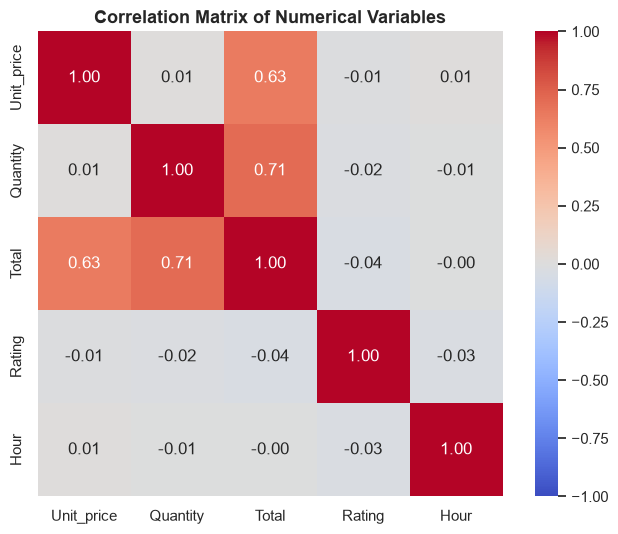

In [24]:
num_cols = ["Unit_price", "Quantity", "Total", "Rating", "Hour"]
corr = df[num_cols].corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.savefig("../images/09_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**What the important correlations mean:**
- **Quantity ↔ Total (≈ 0.71)** and **Unit price ↔ Total (≈ 0.63)**: both are moderately strong and positive. This is expected, because `Total` is calculated from price × quantity — it is arithmetic, not a discovery.
- **Unit price ↔ Quantity (≈ 0.01)**: almost zero. Customers do not buy more or fewer units because an item is cheaper or more expensive in this data.
- **Rating ↔ everything else (close to 0)**: rating is not linearly related to sale amount, price, quantity or time of day.

⚠️ **Correlation does not prove causation.** These numbers only describe how variables move together in this dataset.

## 10. Outlier Analysis

We use boxplots to look for unusual values. We **do not remove** any outliers automatically.

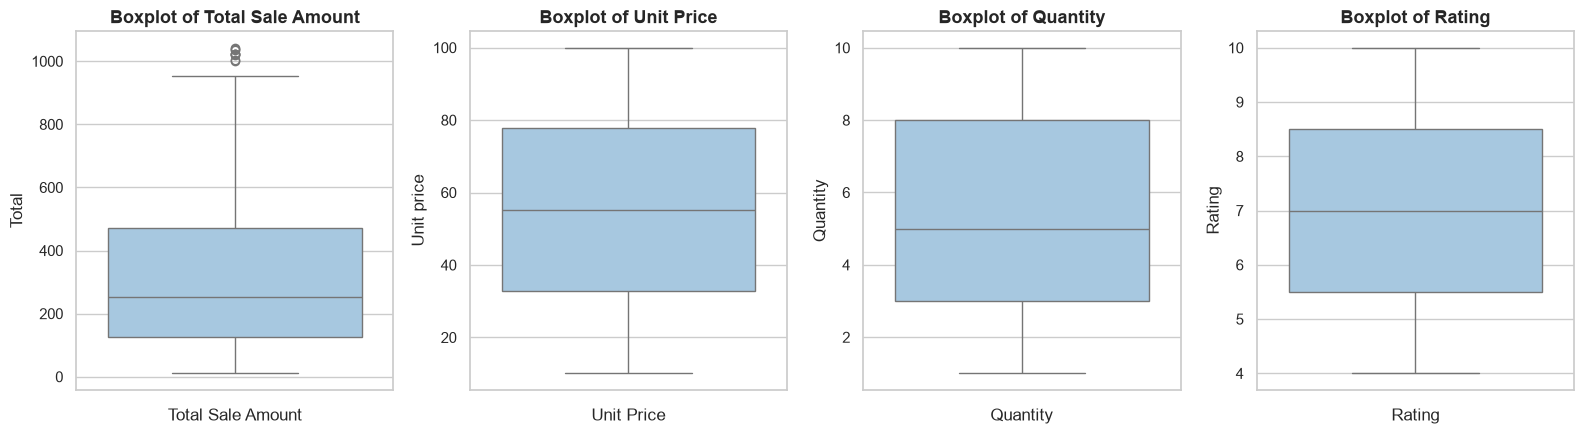

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))

for ax, col, title in zip(
    axes,
    ["Total", "Unit_price", "Quantity", "Rating"],
    ["Total Sale Amount", "Unit Price", "Quantity", "Rating"],
):
    sns.boxplot(data=df, y=col, ax=ax, color="#9ECAE9")
    ax.set_title(f"Boxplot of {title}")
    ax.set_xlabel(title)
    ax.set_ylabel(col.replace("_", " "))

plt.tight_layout()
plt.savefig("../images/10_outlier_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

In [26]:
# Count outliers with the IQR rule (values beyond 1.5 x IQR from the quartiles)
for col in ["Total", "Unit_price", "Quantity", "Rating"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col:11s} -> outliers: {n}  (valid range {low:.1f} to {high:.1f})")

Total       -> outliers: 9  (valid range -396.0 to 991.7)
Unit_price  -> outliers: 0  (valid range -34.7 to 145.5)
Quantity    -> outliers: 0  (valid range -4.5 to 15.5)
Rating      -> outliers: 0  (valid range 1.0 to 13.0)


In [27]:
# Look at the high-value invoices
df.nlargest(9, "Total")[["Invoice_ID", "Branch", "Product_line", "Unit_price", "Quantity", "Total"]].round(2)

,Invoice_ID,Branch,Product_line,Unit_price,Quantity,Total
350,860-79-0874,C,Fashion accessories,99.30,10,1042.65
167,687-47-8271,A,Fashion accessories,98.98,10,1039.29
557,283-26-5248,C,Food and beverages,98.52,10,1034.46
699,751-41-9720,C,Home and lifestyle,97.50,10,1023.75
996,303-96-2227,B,Home and lifestyle,97.38,10,1022.49
792,744-16-7898,B,Home and lifestyle,97.37,10,1022.38
422,271-88-8734,C,Fashion accessories,97.21,10,1020.70
166,234-65-2137,C,Home and lifestyle,95.58,10,1003.59
357,554-42-2417,C,Sports and travel,95.44,10,1002.12


**Interpretation:**
- Only `Total` shows outliers: **9 invoices** above the IQR upper limit (all between about 1,002 and 1,043). The other variables have none.
- These are **legitimate transactions**: each has the maximum quantity (10 units) combined with a very high unit price (about 95–99). They are consistent with `Total = price × quantity`, not data errors.

**Decision:** we keep all of them. They represent valuable big-basket purchases.

## 11. Business Questions

All answers below are calculated from the dataset.

### 1. Which branch generates the highest sales?

In [28]:
branch_sales = df.groupby("Branch")["Total"].sum().sort_values(ascending=False)
print(branch_sales.round(2))
print()
print((branch_sales / branch_sales.sum() * 100).round(1).astype(str) + " % of total")

Branch
C    110568.71
A    106200.37
B    106197.67
Name: Total, dtype: float64

Branch
C    34.2 % of total
A    32.9 % of total
B    32.9 % of total
Name: Total, dtype: str


### 2. Which product line performs best?

In [29]:
print(df.groupby("Product_line")["Total"].sum().sort_values(ascending=False).round(2))

Product_line
Food and beverages        56144.84
Sports and travel         55122.83
Electronic accessories    54337.53
Fashion accessories       54305.90
Home and lifestyle        53861.91
Health and beauty         49193.74
Name: Total, dtype: float64


### 3. Which payment method is most common?

In [30]:
print(df["Payment"].value_counts())

Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64


### 4. Which customer type generates more revenue?

In [31]:
print(df.groupby("Customer_type")["Total"].agg(["sum", "mean", "count"]).round(2))

                     sum    mean  count
Customer_type                          
Member         164223.44  327.79    501
Normal         158743.30  318.12    499


### 5. Which gender contributes more sales?

In [32]:
print(df.groupby("Gender")["Total"].agg(["sum", "mean", "count"]).round(2))

              sum    mean  count
Gender                          
Female  167882.92  335.10    501
Male    155083.82  310.79    499


### 6. What are the busiest sales periods?

In [33]:
print("Top 3 hours (by sales):")
print(df.groupby("Hour")["Total"].sum().nlargest(3).round(2))
print()
print("Top 3 days of week (by sales):")
print(df.groupby("Day_of_week")["Total"].sum().nlargest(3).round(2))
print()
print("Number of transactions by hour (top 3):")
print(df["Hour"].value_counts().head(3))

Top 3 hours (by sales):
Hour
19    39699.51
13    34723.23
10    31421.48
Name: Total, dtype: float64

Top 3 days of week (by sales):
Day_of_week
Saturday    56120.81
Tuesday     51482.25
Thursday    45349.25
Name: Total, dtype: float64

Number of transactions by hour (top 3):
Hour
19    113
13    103
15    102
Name: count, dtype: int64


### 7. Which products have the highest average transaction value?

In [34]:
print(df.groupby("Product_line")["Total"].mean().sort_values(ascending=False).round(2))

Product_line
Home and lifestyle        336.64
Sports and travel         332.07
Health and beauty         323.64
Food and beverages        322.67
Electronic accessories    319.63
Fashion accessories       305.09
Name: Total, dtype: float64


### 8. Are there noticeable differences between branches?

In [35]:
branch_summary = df.groupby("Branch").agg(
    total_sales=("Total", "sum"),
    avg_invoice=("Total", "mean"),
    median_invoice=("Total", "median"),
    transactions=("Invoice_ID", "count"),
    avg_rating=("Rating", "mean"),
).round(2)
branch_summary

,total_sales,avg_invoice,median_invoice,transactions,avg_rating
Branch,,,,,
A,106200.37,312.35,240.83,340,7.03
B,106197.67,319.87,252.88,332,6.82
C,110568.71,337.10,271.42,328,7.07


In [36]:
# Best product line in each branch
branch_product.idxmax(axis=1)

Branch
A    Home and lifestyle
B     Sports and travel
C    Food and beverages
dtype: str

Branches are similar in total sales, number of transactions and rating. Branch C has a higher **average and median invoice**, and each branch has a different best-selling product line.

### 9. What factors appear to be associated with higher sales?

In [37]:
# Correlation of each numeric variable with Total
print(df[["Unit_price", "Quantity", "Rating", "Hour"]].corrwith(df["Total"]).round(3))

Unit_price    0.634
Quantity      0.706
Rating       -0.036
Hour         -0.003
dtype: float64


In [38]:
# Average Total for a few groups
for col in ["Gender", "Customer_type", "Branch"]:
    print(df.groupby(col)["Total"].mean().round(2))
    print()

Gender
Female    335.10
Male      310.79
Name: Total, dtype: float64

Customer_type
Member    327.79
Normal    318.12
Name: Total, dtype: float64

Branch
A    312.35
B    319.87
C    337.10
Name: Total, dtype: float64



**Quantity** and **unit price** are the factors most associated with higher sales (by definition). Rating and hour show almost no linear relationship. Among categories, female customers and Branch C show slightly higher average invoices.

### 10. Actionable business insights
See the **Key Business Insights** section below.

## 12. Final Insights

## Key Business Insights

**1. Branch C leads, but only slightly.**
- *Finding:* Branch C has the highest sales.
- *Evidence:* 110,569 (34.2% of total) vs 106,200 for A and 106,198 for B; its average invoice is also highest (337.10).
- *Interpretation:* The difference between branches is only about 4%, so no branch is clearly underperforming. Branch C's higher average invoice could be worth studying.

**2. Food and beverages is the top product line; Health and beauty is the lowest.**
- *Finding:* The six product lines are close, with a ~14% gap between top and bottom.
- *Evidence:* Food and beverages 56,145 vs Health and beauty 49,194.
- *Interpretation:* Health and beauty may have room for promotion, especially in Branch A where it is weakest (12,598).

**3. Product preferences differ by branch.**
- *Finding:* Each branch has a different best-selling product line.
- *Evidence:* Best line — A: Home and lifestyle (22,417), B: Sports and travel (19,988), C: Food and beverages (23,767).
- *Interpretation:* Stock and promotions could be adapted per branch rather than applied uniformly.

**4. Evening and Saturday are the peak periods.**
- *Finding:* 19:00 is the busiest hour and Saturday the strongest day.
- *Evidence:* 19:00 = 39,700 in sales (113 transactions); Saturday = 56,121, Monday (lowest) = 37,899.
- *Interpretation:* Staffing should be strongest in the evening and on Saturdays; Monday may be a good day for promotions.

**5. Female customers spend more per invoice.**
- *Finding:* Female customers contribute more sales.
- *Evidence:* 167,883 vs 155,084 (male). Average invoice 335.10 vs 310.79, with almost the same number of transactions (501 vs 499).
- *Interpretation:* The gap comes from larger invoices, not more visits. Marketing to this group may be effective.

**6. Members spend only slightly more than Normal customers.**
- *Finding:* Members: 164,223 vs Normal: 158,743 (about 3.5% more); average invoice 327.79 vs 318.12.
- *Interpretation:* The membership program shows only a small difference in spending in this data, so its value may need review.

**7. Cash and Ewallet dominate payments.**
- *Finding:* Credit card is the least used method.
- *Evidence:* Ewallet 345, Cash 344, Credit card 311 transactions; Cash has the highest sales (112,207).
- *Interpretation:* Digital payment is as common as cash; the supermarket should keep all three options.

**8. Customer rating is not related to the sale amount.**
- *Finding:* Rating has almost no correlation with `Total`.
- *Evidence:* correlation = -0.04; the average rating is about 7.0 with a range of 4–10.
- *Interpretation:* Satisfaction does not depend on how much customers spend. Ratings stay moderate everywhere, suggesting overall improvement could be explored through other data.

**9. High-value invoices are legitimate big purchases.**
- *Finding:* Only 9 invoices are outliers in `Total`.
- *Evidence:* All are about 1,002–1,043; each has quantity = 10 and a unit price of about 95–99.
- *Interpretation:* They are not errors. Encouraging bigger baskets (bundles, multi-buy offers) can increase sales.

**10. Data quality note.**
- *Finding:* `Gross_income` equals `Tax`, and the margin column is constant.
- *Interpretation:* These columns cannot be used to judge profitability. Real cost data would be needed.

## 13. Conclusion

**What was discovered:** The dataset is clean (no missing values or duplicates) and well balanced. The three branches have similar total sales (C is slightly ahead), and the six product lines are also close to each other.

**Patterns found:**
- Sales peak in the **evening (19:00)** and on **Saturdays**.
- Each branch has a **different best product line**.
- Female customers have a higher average invoice.
- Customer **rating is unrelated** to sale amount, and `Total` is driven by quantity and unit price (as expected).

**Limitations:** The data covers only 3 months and 1,000 invoices, so seasonality and long-term trends cannot be studied. Real profit cannot be measured because the margin columns carry no extra information.

**Future work:**
- Test whether the differences between branches and genders are statistically significant.
- Study customer behavior with a longer time period and customer IDs.
- Investigate what drives customer ratings (it is not the amount spent).
- Use the real cost of goods to analyse profit.